# Are these SHAP explanations faithful?

Notebook 01 showed that SHAP marks words like "enjoyed" and "beautiful" as
important. That looks convincing, but looking convincing is not evidence. An
explanation is faithful only if the text it calls important is the text the
model actually relies on.

This notebook tests that claim directly. For each review, rank spans of text by
SHAP importance, cut some of them, and measure how far the predicted
probability moves.

- **Sufficiency** cuts the *least* important spans. A faithful ranking discards
  only noise, so the output should barely move. **Lower is better.**
- **Comprehensiveness** cuts the *most* important spans. A faithful ranking has
  identified what the model depends on, so the output should move a lot.
  **Higher is better.**

Neither number means anything on its own. Masked text contains `...` markers and
is off the distribution the encoder was trained on, so *some* movement is
guaranteed regardless of explanation quality. Every measurement is therefore run
a second time against a **random control**: the same attribution values,
permuted within each review so only the ranking is randomized. Both arms take
the identical distribution shift, so the gap between them is the real signal.

## Spans, not just single words

A span is a run of consecutive words, and `chunk_size` sets its length. Size 1
scores every word on its own. Larger sizes ask a different question: can SHAP
identify which *regions* of a review matter, and does aggregating over a span
average away per word noise?

Scoring a span requires combining the attributions inside it, and the three ways
of doing that disagree precisely when a span holds values that cancel:

- `absolute_sum`, the size of the summed signed values. Shapley values are
  additive, so this is the predicted output shift from removing the whole span.
  A span holding +0.05 and -0.05 scores 0, correctly marking it cheap to cut.
- `sum_absolute`, the total magnitude regardless of direction. That same span
  scores 0.10 and is treated as important.
- `max_absolute`, the single strongest word in the span, so one decisive word
  protects its neighbours.

At size 1 all three reduce to the absolute value of a single word, which the
checks below use as a consistency test.

Words are the atomic unit throughout. The masker splits on whitespace so
contractions such as "isn't" stay intact rather than splitting into "isn'" and
"t", which would scatter negation across two separate attributions.

## Configuration

In [1]:
from pathlib import Path

from textfaith.faithfulness import ABSOLUTE_SUM, MAX_ABSOLUTE, SUM_ABSOLUTE

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHECKPOINT_DIRECTORY = PROJECT_ROOT / "artifacts" / "sample_2000"

OBSERVATION_COUNT = 100
PERCENTILES = [10, 20, 30, 40, 50]
CHUNK_SIZES = [1, 4, 8]
COMBINATIONS = [ABSOLUTE_SUM, SUM_ABSOLUTE, MAX_ABSOLUTE]
RANDOM_SEED = 42

ATTRIBUTIONS_PATH = CHECKPOINT_DIRECTORY / f"word_attributions_{OBSERVATION_COUNT}.joblib"

print(f"Checkpoint: {CHECKPOINT_DIRECTORY}")
print(f"Percentiles: {PERCENTILES}")
print(f"Chunk sizes: {CHUNK_SIZES}")
print(f"Combinations: {COMBINATIONS}")

Checkpoint: /home/user/projects/shapley/artifacts/sample_2000
Percentiles: [10, 20, 30, 40, 50]
Chunk sizes: [1, 4, 8]
Combinations: ['absolute_sum', 'sum_absolute', 'max_absolute']


/home/user/projects/shapley/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the classifier and sample the reviews

`load_predictor` rebuilds the exact text to probability pipeline the checkpoint
was trained with. That whole pipeline is the unit under test, because the
classification head alone consumes embeddings rather than text and so cannot be
masked.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

from textfaith.checkpoint import load_predictor

predict_probabilities, tokenizer = load_predictor(CHECKPOINT_DIRECTORY)

test_reviews = pd.read_parquet(CHECKPOINT_DIRECTORY / "test.parquet")
sampled_reviews, _ = train_test_split(
    test_reviews,
    train_size=OBSERVATION_COUNT,
    random_state=RANDOM_SEED,
    stratify=test_reviews["label"],
)
texts = sampled_reviews["text"].tolist()

print(f"Sampled {len(texts)} of {len(test_reviews)} test reviews")
print(f"Class balance: {sampled_reviews['label'].value_counts().to_dict()}")
print(f"Median word count: {int(sampled_reviews['text'].str.split().str.len().median())}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15821.86it/s]

Sampled 100 of 400 test reviews
Class balance: {0: 50, 1: 50}
Median word count: 174


## Compute the word level SHAP attributions

Signed, not absolute. Shapley additivity means the expected shift from removing
a set of words is the sum of their signed values, so discarding the signs here
would make `absolute_sum` impossible to compute downstream.

This is the expensive step, roughly 20 to 25 minutes for 100 reviews on 8 CPU
cores, and it dominates everything else. The result is cached, after which every
chunk size, combination, and percentile below is nearly free.

In [3]:
import joblib

from textfaith.faithfulness import build_word_masker, compute_word_attributions

masker = build_word_masker()

if ATTRIBUTIONS_PATH.exists():
    word_attributions = joblib.load(ATTRIBUTIONS_PATH)
    print("Loaded cached attributions")
else:
    print("Explaining, expect roughly 20 to 25 minutes")
    word_attributions = compute_word_attributions(predict_probabilities, texts, masker)
    joblib.dump(word_attributions, ATTRIBUTIONS_PATH)

word_counts = [len(attribution) for attribution in word_attributions]
negative_share = sum((attribution < 0).sum() for attribution in word_attributions) / sum(word_counts)
print(f"Attributions for {len(word_attributions)} reviews")
print(f"Words per review: min {min(word_counts)}, median {sorted(word_counts)[len(word_counts) // 2]}, max {max(word_counts)}")
print(f"Share of words pushing against the predicted class: {negative_share:.1%}")

Loaded cached attributions
Attributions for 100 reviews
Words per review: min 37, median 178, max 405
Share of words pushing against the predicted class: 44.6%


## Correctness checks before trusting any number

Two cheap invariants that between them catch most ways this can go wrong.

Cutting at percentile 0 keeps every chunk, so the masker must reproduce the
original string and the measured shift must be exactly zero. That one assertion
covers an off by one in the keep mask, a misuse of the masker, and a reshape
error in the batched prediction.

At chunk size 1 the three combinations are different formulas over a single
value, so they must agree exactly. If they diverge, the chunking is misaligned.

In [4]:
import numpy as np

from textfaith.faithfulness import measure_sufficiency

no_cut_shift = measure_sufficiency(
    predict_probabilities, texts, [0], masker, word_attributions
)
assert np.array_equal(no_cut_shift, np.zeros_like(no_cut_shift)), "Cutting nothing moved the output"
print(f"Cutting nothing moves the output by {np.abs(no_cut_shift).max()}, as required")

single_word_results = [
    measure_sufficiency(
        predict_probabilities, texts, PERCENTILES, masker, word_attributions,
        chunk_size=1, combination=combination,
    )
    for combination in COMBINATIONS
]
for other in single_word_results[1:]:
    assert np.allclose(single_word_results[0], other), "Combinations disagree at chunk size 1"
print("All three combinations agree at chunk size 1, as required")

Cutting nothing moves the output by 0.0, as required


All three combinations agree at chunk size 1, as required


## Sweep chunk size and combination

Every cell of the grid is measured for SHAP and for the shuffled control, in
both directions.

In [5]:
from textfaith.faithfulness import measure_comprehensiveness, shuffle_attributions

shuffled_attributions = shuffle_attributions(word_attributions, RANDOM_SEED)

records = []
for chunk_size in CHUNK_SIZES:
    for combination in COMBINATIONS:
        for source, attributions in [
            ("shap", word_attributions),
            ("random", shuffled_attributions),
        ]:
            for direction, measure in [
                ("sufficiency", measure_sufficiency),
                ("comprehensiveness", measure_comprehensiveness),
            ]:
                records.append(
                    {
                        "chunk_size": chunk_size,
                        "combination": combination,
                        "source": source,
                        "direction": direction,
                        "values": measure(
                            predict_probabilities, texts, PERCENTILES, masker,
                            attributions, chunk_size=chunk_size, combination=combination,
                        ),
                    }
                )

print(f"Measured {len(records)} grid cells, each of shape {records[0]['values'].shape}")

Measured 36 grid cells, each of shape (100, 5)


## Results

Group means alone would overstate the evidence. Every cell runs on the same
reviews, so the SHAP and control arms are paired and the difference belongs per
review. The advantage column is that paired statistic, the mean advantage
divided by its standard error, averaged across percentiles. Above roughly 2 the
gap is larger than sampling noise.

In [6]:
def paired_advantage(better: np.ndarray, worse: np.ndarray) -> float:
    '''Mean paired advantage divided by its standard error, averaged over percentiles.'''
    differences = better - worse
    standard_errors = differences.std(axis=0, ddof=1) / np.sqrt(differences.shape[0])
    return float(np.mean(differences.mean(axis=0) / standard_errors))


def lookup(chunk_size, combination, source, direction):
    for record in records:
        if (record["chunk_size"], record["combination"], record["source"], record["direction"]) == (
            chunk_size, combination, source, direction
        ):
            return record["values"]
    raise KeyError((chunk_size, combination, source, direction))


rows = []
for chunk_size in CHUNK_SIZES:
    for combination in COMBINATIONS:
        sufficiency = lookup(chunk_size, combination, "shap", "sufficiency")
        sufficiency_control = lookup(chunk_size, combination, "random", "sufficiency")
        comprehensiveness = lookup(chunk_size, combination, "shap", "comprehensiveness")
        comprehensiveness_control = lookup(chunk_size, combination, "random", "comprehensiveness")
        rows.append(
            {
                "chunk_size": chunk_size,
                "combination": combination,
                "sufficiency": sufficiency.mean(),
                "sufficiency_control": sufficiency_control.mean(),
                "sufficiency_ratio": sufficiency_control.mean() / sufficiency.mean(),
                "sufficiency_t": paired_advantage(sufficiency_control, sufficiency),
                "comprehensiveness": comprehensiveness.mean(),
                "comprehensiveness_control": comprehensiveness_control.mean(),
                "comprehensiveness_ratio": comprehensiveness.mean() / comprehensiveness_control.mean(),
                "comprehensiveness_t": paired_advantage(
                    comprehensiveness, comprehensiveness_control
                ),
            }
        )

grid = pd.DataFrame(rows).set_index(["chunk_size", "combination"])
print("Mean absolute probability shift, averaged over percentiles")
grid
# print(grid.round(4).to_string())

Mean absolute probability shift, averaged over percentiles

                         sufficiency  sufficiency_control  sufficiency_ratio  sufficiency_t  comprehensiveness  comprehensiveness_control  comprehensiveness_ratio  comprehensiveness_t
chunk_size combination                                                                                                                                                                 
1          absolute_sum       0.0386               0.0764             1.9792         5.7310             0.1088                     0.0825                   1.3180               2.7494
           sum_absolute       0.0386               0.0764             1.9792         5.7310             0.1088                     0.0825                   1.3180               2.7494
           max_absolute       0.0386               0.0764             1.9792         5.7310             0.1088                     0.0825                   1.3180               2.7494
4          absolute_

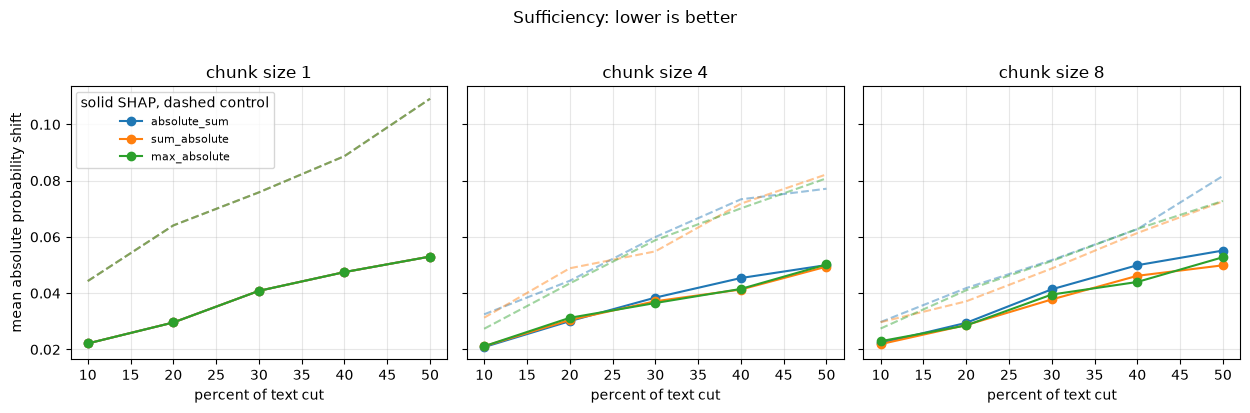

In [7]:
import matplotlib.pyplot as plt

colors = dict(zip(COMBINATIONS, ["C0", "C1", "C2"]))
figure, axes = plt.subplots(1, len(CHUNK_SIZES), figsize=(4.2 * len(CHUNK_SIZES), 4.0), sharey=True)

for axis, chunk_size in zip(axes, CHUNK_SIZES):
    for combination in COMBINATIONS:
        axis.plot(
            PERCENTILES,
            lookup(chunk_size, combination, "shap", "sufficiency").mean(axis=0),
            "-o", color=colors[combination], label=f"{combination}",
        )
        axis.plot(
            PERCENTILES,
            lookup(chunk_size, combination, "random", "sufficiency").mean(axis=0),
            "--", color=colors[combination], alpha=0.45,
        )
    axis.set_title(f"chunk size {chunk_size}")
    axis.set_xlabel("percent of text cut")
    axis.grid(alpha=0.3)

axes[0].set_ylabel("mean absolute probability shift")
axes[0].legend(title="solid SHAP, dashed control", fontsize=8)
figure.suptitle("Sufficiency: lower is better", y=1.02)
figure.tight_layout()
plt.show()

## Reading of the result

Ranking by raw shift would be a trap here. Chunking lowers the *control* as well,
because cutting one contiguous block damages a review less than scattering the
same number of cuts across it. The honest measure of explanation quality is
therefore the separation from the control, not the raw number.

In [8]:
print("Sufficiency, ranked by separation from the control rather than raw shift")
print()
print(grid[["sufficiency", "sufficiency_control", "sufficiency_ratio", "sufficiency_t"]]
      .sort_values("sufficiency_ratio", ascending=False).round(3).to_string())
print()

single_word = grid.loc[(1, ABSOLUTE_SUM)]
print(f"Raw shift looks best at {grid['sufficiency'].idxmin()} "
      f"({grid['sufficiency'].min():.4f} against {single_word['sufficiency']:.4f} for single words),")
print("but that improvement is not explanation quality. Over the same range the")
print(f"control falls from {single_word['sufficiency_control']:.4f} to "
      f"{grid['sufficiency_control'].min():.4f}, so SHAP's edge shrinks from "
      f"{single_word['sufficiency_ratio']:.2f}x to {grid['sufficiency_ratio'].min():.2f}x.")
print()

print("Separation by chunk size (higher is better):")
for chunk_size in CHUNK_SIZES:
    block = grid.loc[chunk_size]
    print(f"  size {chunk_size}: sufficiency {block['sufficiency_ratio'].max():.2f}x "
          f"(t {block['sufficiency_t'].max():.1f}), "
          f"comprehensiveness {block['comprehensiveness_ratio'].max():.2f}x "
          f"(t {block['comprehensiveness_t'].max():.1f})")
print()

signed_minus_magnitude = (
    grid.xs(SUM_ABSOLUTE, level="combination")["sufficiency"]
    - grid.xs(ABSOLUTE_SUM, level="combination")["sufficiency"]
)
print("Does signed aggregation beat magnitude aggregation?")
print("Shapley additivity predicts absolute_sum should win, since the expected")
print("shift from removing a span is the sum of its signed values.")
print("sum_absolute minus absolute_sum, per chunk size (positive favours absolute_sum):")
print(signed_minus_magnitude.round(4).to_string())
if (signed_minus_magnitude <= 0).all():
    print("The prediction does not hold. Magnitude aggregation ranks at least as")
    print("well everywhere, so cancelling spans are not in fact safe to cut. Their")
    print("words still carry content, and removing them still perturbs the")
    print("mean pooled embedding that the classifier reads.")
print()

if (grid["sufficiency_t"] >= 2.0).all():
    print("Every chunk size and combination still separates from its control, so the")
    print("attributions remain informative at all granularities tested. Single word")
    print("scoring gives the cleanest signal for sufficiency; chunking pays off only")
    print("for comprehensiveness.")
else:
    weak = grid.index[grid["sufficiency_t"] < 2.0].tolist()
    print(f"These cells did not separate convincingly from the control: {weak}")

Sufficiency, ranked by separation from the control rather than raw shift

                         sufficiency  sufficiency_control  sufficiency_ratio  sufficiency_t
chunk_size combination                                                                     
1          absolute_sum        0.039                0.076              1.979          5.731
           sum_absolute        0.039                0.076              1.979          5.731
           max_absolute        0.039                0.076              1.979          5.731
4          sum_absolute        0.036                0.058              1.611          3.812
           absolute_sum        0.037                0.057              1.556          3.764
           max_absolute        0.036                0.056              1.554          3.324
8          max_absolute        0.038                0.051              1.361          2.562
           sum_absolute        0.037                0.050              1.353          2.773
      